In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    roc_auc_score,
    mean_absolute_error,
    r2_score,
)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier,
    RandomForestRegressor,
)
from sklearn.svm import SVC

import xgboost as xgb


In [ ]:
from google.colab import files

uploaded = files.upload()
print(uploaded.keys())


Saving dse_5shares_2years_with_news_mock.csv to dse_5shares_2years_with_news_mock.csv
dict_keys(['dse_5shares_2years_with_news_mock.csv'])


In [ ]:
import pandas as pd
import numpy as np
csv_name = 'dse_5shares_2years_with_news_mock.csv'
df = pd.read_csv(csv_name, parse_dates=['Date'])
df = df.sort_values(['Code', 'Date']).reset_index(drop=True)
if 'NewsHeadlines' not in df.columns:
    df['NewsHeadlines'] = ''
if 'NewsSentiment' not in df.columns:
    df['NewsSentiment'] = 0.0
if 'NewsCount' not in df.columns:
    df['NewsCount'] = 0

df['NewsHeadlines'] = df['NewsHeadlines'].fillna('')
df['NewsSentiment'] = df['NewsSentiment'].fillna(0.0)
df['NewsCount']     = df['NewsCount'].fillna(0).astype(int)


def compute_rsi_series(close_series: pd.Series, window: int = 14) -> pd.Series:
    delta = close_series.diff()

    gain = delta.where(delta > 0, 0.0)
    loss = -delta.where(delta < 0, 0.0)

    avg_gain = gain.rolling(window=window, min_periods=window).mean()
    avg_loss = loss.rolling(window=window, min_periods=window).mean()

    rs = avg_gain / (avg_loss + 1e-9)
    rsi = 100.0 - (100.0 / (1.0 + rs))
    return rsi

def add_technical_features(df_prices: pd.DataFrame) -> pd.DataFrame:
    df_ = df_prices.copy()
    df_ = df_.sort_values(['Code', 'Date']).reset_index(drop=True)
    by_code_close = df_.groupby('Code')['Close']

    # Returns
    df_['return_1d'] = by_code_close.transform(lambda s: s.pct_change())
    df_['return_5d'] = by_code_close.transform(lambda s: s.pct_change(5))

    # Volatility
    df_['volatility_5d'] = by_code_close.transform(
        lambda s: s.pct_change().rolling(5).std()
    )

    # Moving averages
    df_['ma_5'] = by_code_close.transform(lambda s: s.rolling(5).mean())
    df_['ma_10'] = by_code_close.transform(lambda s: s.rolling(10).mean())

    # RSI
    df_['rsi_14'] = by_code_close.transform(lambda s: compute_rsi_series(s, window=14))

    return df_

df = add_technical_features(df)
df['Close_next'] = df.groupby('Code')['Close'].shift(-1)
df['y_up'] = (df['Close_next'] > df['Close']).astype(int)

df['NewsHeadlines'] = df['NewsHeadlines'].fillna('')
df['NewsSentiment'] = df['NewsSentiment'].fillna(0.0)
df['NewsCount']     = df['NewsCount'].fillna(0).astype(int)
df[['Date', 'Code', 'Close', 'ma_5', 'ma_10', 'rsi_14', 'NewsCount', 'NewsSentiment']].head()



,Date,Code,Close,ma_5,ma_10,rsi_14,NewsCount,NewsSentiment
0,2024-01-01,BATBC,532.27,NaN,NaN,NaN,1,-1
1,2024-01-02,BATBC,536.93,NaN,NaN,NaN,1,0
2,2024-01-03,BATBC,541.59,NaN,NaN,NaN,3,-1
3,2024-01-04,BATBC,541.36,NaN,NaN,NaN,1,1
4,2024-01-05,BATBC,538.10,538.05,NaN,NaN,3,2


In [ ]:
# Classification models
feature_cols_common = [
    'Open', 'High', 'Low', 'Close', 'Volume',
    'return_1d', 'return_5d', 'volatility_5d',
    'ma_5', 'ma_10', 'rsi_14',
    'NewsSentiment', 'NewsCount',
]

df_model = df.dropna(subset=feature_cols_common + ['y_up', 'Close_next']).reset_index(drop=True)

X_cls = df_model[feature_cols_common].values
y_cls = df_model['y_up'].values

X_train_cls, X_test_cls, y_train_cls, y_test_cls = train_test_split(
    X_cls, y_cls, test_size=0.2, random_state=42, stratify=y_cls
)

scaler_cls = StandardScaler()
X_train_cls_scaled = scaler_cls.fit_transform(X_train_cls)
X_test_cls_scaled = scaler_cls.transform(X_test_cls)

results = []

# Logistic Regression
logreg = LogisticRegression(max_iter=1000)
logreg.fit(X_train_cls_scaled, y_train_cls)
y_pred = logreg.predict(X_test_cls_scaled)
y_prob = logreg.predict_proba(X_test_cls_scaled)[:, 1]
results.append({
    'Model': 'Logistic Regression',
    'Accuracy': accuracy_score(y_test_cls, y_pred),
    'F1 Score': f1_score(y_test_cls, y_pred),
    'ROC AUC': roc_auc_score(y_test_cls, y_prob),
})

# Random Forest Classifier
rf_clf = RandomForestClassifier(n_estimators=200, random_state=42)
rf_clf.fit(X_train_cls, y_train_cls)
y_pred = rf_clf.predict(X_test_cls)
y_prob = rf_clf.predict_proba(X_test_cls)[:, 1]
results.append({
    'Model': 'Random Forest (Classifier)',
    'Accuracy': accuracy_score(y_test_cls, y_pred),
    'F1 Score': f1_score(y_test_cls, y_pred),
    'ROC AUC': roc_auc_score(y_test_cls, y_prob),
})

# Gradient Boosting Classifier
gb_clf = GradientBoostingClassifier(random_state=42)
gb_clf.fit(X_train_cls_scaled, y_train_cls)
y_pred = gb_clf.predict(X_test_cls_scaled)
y_prob = gb_clf.predict_proba(X_test_cls_scaled)[:, 1]
results.append({
    'Model': 'Gradient Boosting (Classifier)',
    'Accuracy': accuracy_score(y_test_cls, y_pred),
    'F1 Score': f1_score(y_test_cls, y_pred),
    'ROC AUC': roc_auc_score(y_test_cls, y_prob),
})

# SVM (RBF)
svm_clf = SVC(kernel='rbf', probability=True, random_state=42)
svm_clf.fit(X_train_cls_scaled, y_train_cls)
y_pred = svm_clf.predict(X_test_cls_scaled)
y_prob = svm_clf.predict_proba(X_test_cls_scaled)[:, 1]
results.append({
    'Model': 'SVM (RBF)',
    'Accuracy': accuracy_score(y_test_cls, y_pred),
    'F1 Score': f1_score(y_test_cls, y_pred),
    'ROC AUC': roc_auc_score(y_test_cls, y_prob),
})

# XGBoost Classifier
xgb_clf = xgb.XGBClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=4,
    subsample=0.9,
    colsample_bytree=0.8,
    random_state=42,
    eval_metric='logloss',
)
xgb_clf.fit(X_train_cls, y_train_cls)
y_pred = xgb_clf.predict(X_test_cls)
y_prob = xgb_clf.predict_proba(X_test_cls)[:, 1]
results.append({
    'Model': 'XGBoost (Classifier)',
    'Accuracy': accuracy_score(y_test_cls, y_pred),
    'F1 Score': f1_score(y_test_cls, y_pred),
    'ROC AUC': roc_auc_score(y_test_cls, y_prob),
})

results_df = pd.DataFrame(results)
results_df


,Model,Accuracy,F1 Score,ROC AUC
0,Logistic Regression,0.508876,0.422274,0.502895
1,Random Forest (Classifier),0.540434,0.540434,0.533203
2,Gradient Boosting (Classifier),0.506903,0.497992,0.512974
3,SVM (RBF),0.514793,0.483193,0.493166
4,XGBoost (Classifier),0.485207,0.481113,0.510118


In [ ]:
X_reg = df_model[feature_cols_common].values
y_reg = df_model['Close_next'].values

X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X_reg, y_reg, test_size=0.2, random_state=42, shuffle=False
)

scaler_reg = StandardScaler()
X_train_reg_scaled = scaler_reg.fit_transform(X_train_reg)
X_test_reg_scaled = scaler_reg.transform(X_test_reg)

rf_reg = RandomForestRegressor(n_estimators=300, random_state=42)
rf_reg.fit(X_train_reg, y_train_reg)
y_pred_reg = rf_reg.predict(X_test_reg)

mae = mean_absolute_error(y_test_reg, y_pred_reg)
r2 = r2_score(y_test_reg, y_pred_reg)
print('Random Forest Regressor (Tomorrow Close Price)')
print('MAE:', mae)
print('R^2:', r2)


Random Forest Regressor (Tomorrow Close Price)
MAE: 13.302991913214816
R^2: -0.1674789577007747


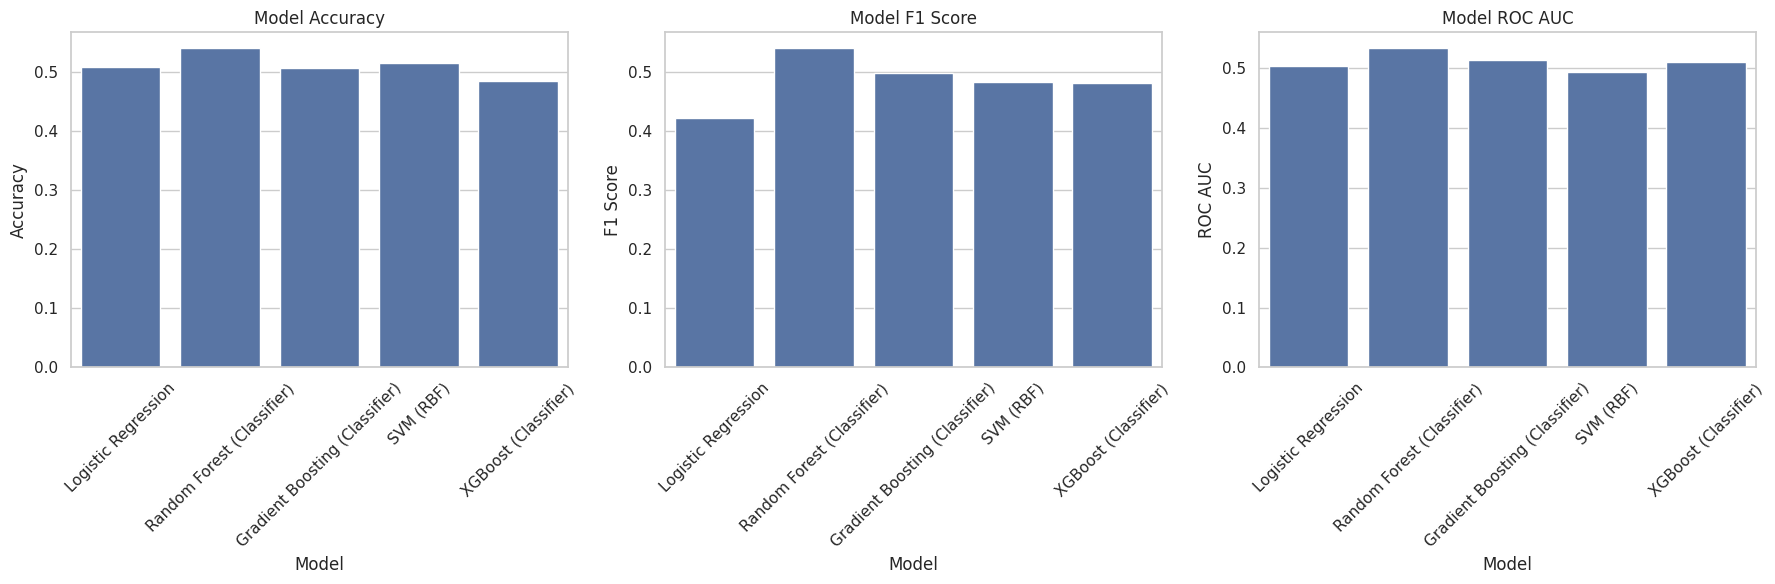

In [ ]:
sns.set(style='whitegrid')
fig, ax = plt.subplots(1, 3, figsize=(18, 6))
sns.barplot(x='Model', y='Accuracy', data=results_df, ax=ax[0])
ax[0].set_title('Model Accuracy')
ax[0].tick_params(axis='x', rotation=45)
sns.barplot(x='Model', y='F1 Score', data=results_df, ax=ax[1])
ax[1].set_title('Model F1 Score')
ax[1].tick_params(axis='x', rotation=45)
sns.barplot(x='Model', y='ROC AUC', data=results_df, ax=ax[2])
ax[2].set_title('Model ROC AUC')
ax[2].tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()


Available share codes:
BATBC, BEXIMCO, BRACBANK, GP, SQURPHARMA
Enter a share CODE (e.g., GP, BATBC, SQURPHARMA): GP

=== Prediction for GP ===
Last close price: 232.25
Predicted tomorrow close: 231.74
Expected change: -0.22%
Probability of price going UP (Logistic Regression): 49.41%
Latest News Sentiment (day-level): +0.0
Number of news headlines used: 1
News sample: GP issues corporate disclosure to exchange


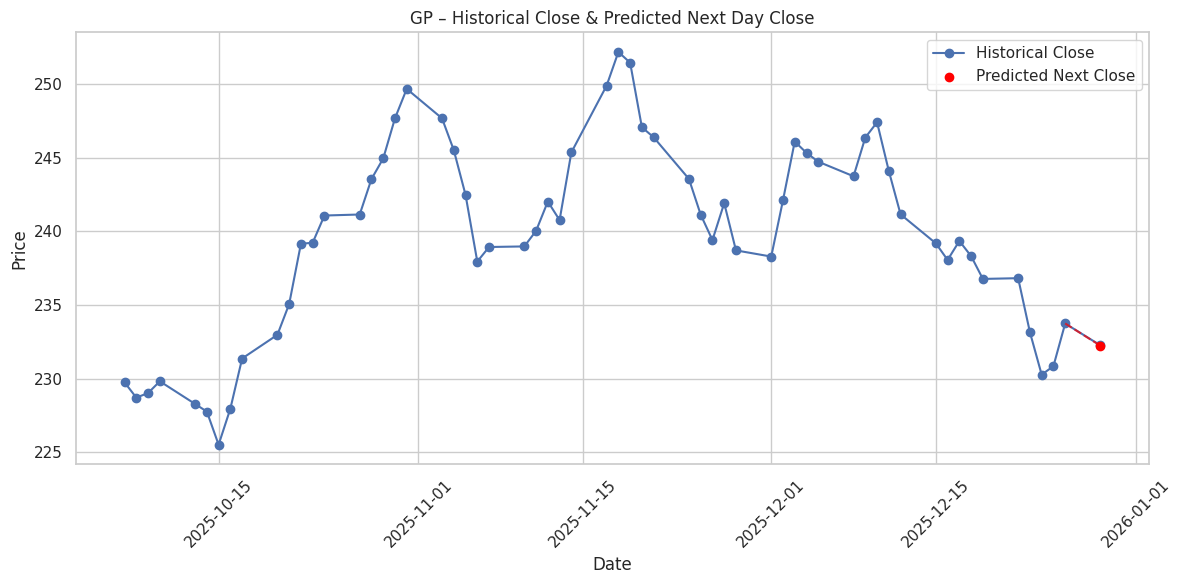

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

def plot_share_with_predicted_next_day(share_code, history_days=60):
    df_share = df[df['Code'] == share_code].sort_values('Date').copy()
    if df_share.empty:
        print(f"No data found for share code: {share_code}")
        return


    df_hist = df_share.tail(history_days).copy()
    df_model_share = df_model[df_model['Code'] == share_code].sort_values('Date')
    if df_model_share.empty:
        print(f"No model-ready rows found for share code: {share_code}")
        return

    latest_row_model = df_model_share.iloc[-1:].copy()


    X_latest = latest_row_model[feature_cols_common].values
    pred_next_close = rf_reg.predict(X_latest)[0]


    last_date = latest_row_model['Date'].iloc[0]
    next_date = last_date + pd.tseries.offsets.BDay(1)

    # Plot
    plt.figure(figsize=(12, 6))
    plt.plot(df_hist['Date'], df_hist['Close'], label='Historical Close', marker='o')
    plt.scatter([next_date], [pred_next_close], color='red', label="Predicted Next Close", zorder=5)
    plt.plot(
        [last_date, next_date],
        [latest_row_model['Close'].iloc[0], pred_next_close],
        linestyle='--',
        color='red',
        alpha=0.7,
    )

    plt.title(f"{share_code} – Historical Close & Predicted Next Day Close")
    plt.xlabel("Date")
    plt.ylabel("Price")
    plt.legend()
    plt.grid(True)
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()




available_codes = sorted(df['Code'].unique())
print('Available share codes:')
print(', '.join(available_codes))

user_code = input("Enter a share CODE (e.g., GP, BATBC, SQURPHARMA): ").strip().upper()

if user_code not in available_codes:
    print(f'Code {user_code} not found.')
else:
    latest_row = df[df['Code'] == user_code].sort_values('Date').iloc[-1:].copy()
    latest_row['NewsHeadlines'] = latest_row['NewsHeadlines'].fillna('')
    latest_row['NewsSentiment'] = latest_row['NewsSentiment'].fillna(0.0)
    latest_row['NewsCount'] = latest_row['NewsCount'].fillna(0).astype(int)

    X_latest = latest_row[feature_cols_common].values
    latest_scaled_cls = scaler_cls.transform(X_latest)
    prob_up = logreg.predict_proba(latest_scaled_cls)[0, 1]

    pred_price = rf_reg.predict(X_latest)[0]
    last_close = float(latest_row['Close'].iloc[0])
    pct_change = (pred_price - last_close) / last_close * 100.0

    print('\n=== Prediction for', user_code, '===')
    print(f'Last close price: {last_close:.2f}')
    print(f'Predicted tomorrow close: {pred_price:.2f}')
    print(f'Expected change: {pct_change:+.2f}%')
    print(f'Probability of price going UP (Logistic Regression): {prob_up:.2%}')
    print(f'Latest News Sentiment (day-level): {float(latest_row["NewsSentiment"].iloc[0]):+.1f}')
    print(f'Number of news headlines used: {int(latest_row["NewsCount"].iloc[0])}')
    print('News sample:', latest_row['NewsHeadlines'].iloc[0][:300])
    history_days = 60
    plot_share_with_predicted_next_day(user_code, history_days=history_days)
